# Applied Machine Learning (CSAI2017P) — Lab Assignment 4
## Customer Churn Prediction

Experiment 5 (Units V–VI) · CO2, CO4

| | |
|---|---|
| Name | *model solution* |
| SAP ID | — |
| Batch | — |
| Due | announced in the lab |
| Lab quiz | LQ4, after submission |

> **This is a worked solution.** Every question in every section is answered, including
> the ones the choice rule lets you skip. Your own submission only needs 2 of 3 in
> Section A and 1 of 2 in Section B.


In [1]:
import sys, time, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn, __import__('matplotlib')):
    print(f"{m.__name__:12s} {m.__version__}")
print(f"{'python':12s} {sys.version.split()[0]}")

numpy        2.4.2
pandas       3.0.0
sklearn      1.8.0
matplotlib   3.10.8
python       3.13.11


## Load the data

One dataset throughout: A2, Telco Customer Churn. `customerID` is dropped — it is a unique string, and one-hot encoding it would create 7,043 columns each true for exactly one customer.

In [2]:
from aml_data import load_telco
from sklearn.model_selection import train_test_split

tel = load_telco()
tel['TotalCharges'] = pd.to_numeric(tel.TotalCharges, errors='coerce').fillna(0)
#  ^^ the 11 blank cells found in LA01

y = (tel.Churn == 'Yes').astype(int)
X = tel.drop(columns=['customerID', 'Churn'])

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
print(f'{len(X_tr):,} train / {len(X_te):,} test  ({y_te.sum()} churners, {(y_te==0).sum()} stayers)')
print(f'{len(num_cols)} numeric, {len(cat_cols)} categorical columns')
print(f'churn rate {y.mean():.1%}')

5,634 train / 1,409 test  (374 churners, 1035 stayers)
4 numeric, 15 categorical columns
churn rate 26.5%


---

# Section A — attempt any 2 of 3

*All three are answered below.*

## A1. Encode and fit

*Dataset: A2. Target: `Churn`.*

a. Build a `ColumnTransformer` with one-hot encoding for categoricals and scaling for numerics.
b. Fit a logistic regression inside the pipeline and report test accuracy.
c. State the churn rate in the data and compare it with your accuracy in two lines.

In [3]:
# A1 — code
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pre = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_cols),
])

lr = Pipeline([('pre', pre),
               ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
lr.fit(X_tr, y_tr)

acc = lr.score(X_te, y_te)
baseline = 1 - y_te.mean()          # predict "stays" for everyone
print(f'features after one-hot encoding: {lr[:-1].transform(X_tr).shape[1]}')
print(f'test accuracy        {acc:.4f}')
print(f'majority baseline    {baseline:.4f}')
print(f'the model contributes {100 * (acc - baseline):.1f} percentage points')

features after one-hot encoding: 40
test accuracy        0.8020
majority baseline    0.7346
the model contributes 6.7 percentage points


**Observation (A1):**

Test accuracy **0.8020** on 1,409 held-out customers. The churn rate is **26.5%**, so a model
that predicted "stays" for everyone would score **73.5%**.

The model is therefore 6.7 percentage points better than a constant answer — real, but far
less impressive than 80% sounds. With an imbalanced target, accuracy is anchored near the
majority-class rate and most of it is earned before the model does anything. That is why
the rest of this assignment is about the confusion matrix rather than about accuracy.

## A2. Confusion matrix

*Dataset: A2.*

a. Print the confusion matrix and the classification report for your A1 model.
b. State the number of churners the model missed.
c. In two lines, say which error costs the company more: a missed churner, or a retention offer sent to someone who was staying.

[[924 111]
 [168 206]]

              precision    recall  f1-score   support

        stay      0.846     0.893     0.869      1035
       churn      0.650     0.551     0.596       374

    accuracy                          0.802      1409
   macro avg      0.748     0.722     0.733      1409
weighted avg      0.794     0.802     0.796      1409

missed churners (false negatives): 168 of 374
false alarms    (false positives): 111
recall on churn: 0.551


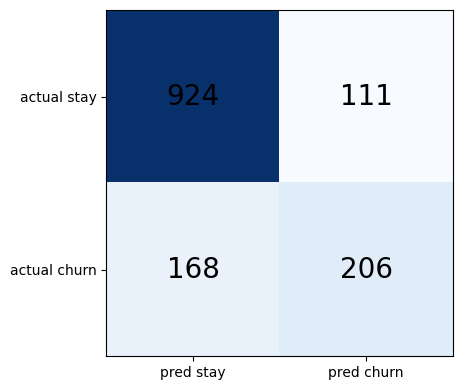

In [4]:
# A2 — code
from sklearn.metrics import confusion_matrix, classification_report

pred = lr.predict(X_te)
cm = confusion_matrix(y_te, pred)        # rows = actual, columns = predicted
print(cm)
print()
print(classification_report(y_te, pred, target_names=['stay', 'churn'], digits=3))

tn, fp, fn, tp = cm.ravel()
print(f'missed churners (false negatives): {fn} of {fn + tp}')
print(f'false alarms    (false positives): {fp}')
print(f'recall on churn: {tp / (tp + fn):.3f}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=20)
ax.set_xticks([0, 1], ['pred stay', 'pred churn'])
ax.set_yticks([0, 1], ['actual stay', 'actual churn'])
plt.tight_layout(); plt.show()

**Observation (A2):**

The matrix is `[[924, 111], [168, 206]]`: 924 stayers correctly left alone, 111 false
alarms, **168 churners missed**, 206 churners caught. Precision on churn 0.650, recall
**0.551** — the model finds a little over half the people who are about to leave, and the
80% accuracy headline hides this completely because the 924 correct stayers dominate the
average.

**(c)** A missed churner costs far more. Losing a customer forfeits the whole remaining
lifetime value of that contract — on this data a median monthly charge around $70, against
an acquisition cost that industry-wide runs to several months of revenue. An unnecessary
retention offer costs only the discount, handed to someone who was already profitable and
now feels valued. The two errors are not symmetric, so accuracy — which treats them as
equal — is the wrong thing to optimise.

## A3. Threshold moving

*Dataset: A2. No retraining — the model is finished.*

a. Take `predict_proba` from your model and re-classify at thresholds 0.5, 0.35 and 0.25.
b. Report precision and recall on the churn class for each.
c. State which threshold you would ship and why, in two lines.

In [5]:
# A3 — code
from sklearn.metrics import precision_score, recall_score

proba = lr.predict_proba(X_te)[:, 1]     # column 1 = P(churn)

rows = []
for t in (0.5, 0.35, 0.25):
    pred_t = (proba >= t).astype(int)
    c = confusion_matrix(y_te, pred_t)
    rows.append({'threshold': t,
                 'precision': precision_score(y_te, pred_t),
                 'recall': recall_score(y_te, pred_t),
                 'missed': c[1, 0], 'false_alarms': c[0, 1], 'flagged': pred_t.sum()})
display(pd.DataFrame(rows).round(3))

# predict() is simply predict_proba() with a 0.5 cutoff hard-coded:
assert (lr.predict(X_te) == (proba >= 0.5).astype(int)).all()
print('predict() == proba >= 0.5 : confirmed')

,threshold,precision,recall,missed,false_alarms,flagged
0,0.50,0.650,0.551,168,111,317
1,0.35,0.569,0.717,106,203,471
2,0.25,0.513,0.829,64,294,604


predict() == proba >= 0.5 : confirmed


**Observation (A3):**

At 0.50 precision is 0.650 and recall 0.551; at 0.35, 0.569 and 0.717; at 0.25, 0.513 and
0.829. Lowering the threshold flags more customers, so it catches more real churners and is
wrong more often about the ones it flags. Nothing is retrained — this is the same model,
read at a different cutoff.

**(c)** I would ship **0.35**. Moving from 0.50 to 0.35 converts 62 missed churners into
caught ones for 92 extra retention offers, and roughly four in seven flagged customers are
genuine. Going on to 0.25 buys 42 more for 91 further offers and drops precision below half
— the campaign becomes mostly discount to people who were never leaving. The right choice
depends on the offer's cost relative to a lost contract: if the offer is nearly free, 0.25
wins; if it is a month of revenue, 0.50 is defensible.

---

# Section B — attempt any 1 of 2

*Both are answered below.*

## B1. Model comparison

*Dataset: A2, the same pipeline for all three.*

a. Train logistic regression, a decision tree (`max_depth=5`) and a random forest on the same pipeline.
b. Report accuracy, precision, recall, F1 and ROC-AUC for each in one table.
c. Name the best model for this problem and defend the choice in 4–6 lines, referring to the cost argument.

,model,accuracy,precision,recall,f1,roc_auc,missed
0,logistic regression,0.802,0.650,0.551,0.596,0.852,168
1,decision tree (depth 5),0.793,0.609,0.618,0.614,0.837,143
2,random forest,0.786,0.634,0.463,0.535,0.826,201


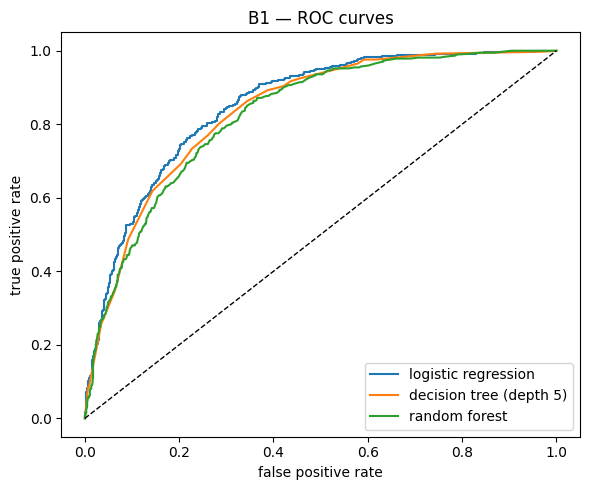

In [6]:
# B1 — code
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve

models = {
    'logistic regression':     LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'decision tree (depth 5)': DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    'random forest':           RandomForestClassifier(n_estimators=300,
                                                      random_state=RANDOM_STATE, n_jobs=-1),
}

rows, curves = [], {}
for name, est in models.items():
    pipe = Pipeline([('pre', pre), ('clf', est)]).fit(X_tr, y_tr)
    pr = pipe.predict(X_te)
    pp = pipe.predict_proba(X_te)[:, 1]      # AUC needs probabilities, not labels
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_te, pr),
                 'precision': precision_score(y_te, pr),
                 'recall': recall_score(y_te, pr),
                 'f1': f1_score(y_te, pr),
                 'roc_auc': roc_auc_score(y_te, pp),
                 'missed': confusion_matrix(y_te, pr)[1, 0]})
    curves[name] = roc_curve(y_te, pp)

display(pd.DataFrame(rows).round(3))

plt.figure(figsize=(6, 5))
for name, (fpr, tpr, _) in curves.items():
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('false positive rate'); plt.ylabel('true positive rate'); plt.legend()
plt.title('B1 — ROC curves'); plt.tight_layout(); plt.show()

**Observation (B1):**

Logistic regression: accuracy 0.802, F1 0.596, ROC-AUC **0.852**. Decision tree: 0.793,
0.614, 0.837. Random forest: 0.786, 0.535, 0.826.

I would ship the **logistic regression**. It has the best ROC-AUC, which measures ranking
quality independently of any threshold — and since A3 showed the threshold is the real
decision, ranking is what I need the model to do well. The decision tree's slightly higher
F1 is an artefact of where its default 0.5 cutoff happens to fall, not of better
discrimination.

The random forest is the worst choice here despite being the most powerful: recall 0.463
means it misses 201 of 374 churners, and the cost argument from A2 says missed churners are
the expensive error. It is also the hardest to explain to the retention team, while the
logistic regression hands them readable coefficients (C1).

All three sit within 0.03 of each other on AUC, so **model choice matters far less here
than threshold choice**.

## B2. Class imbalance

*Dataset: A2.*

a. Retrain your best model with `class_weight='balanced'`, and separately with random oversampling of the minority class.
b. Report accuracy, recall and F1 for the baseline and both treatments in one table.
c. Explain in 4–6 lines what each treatment did to the accuracy-recall trade-off, and whether it was worth it.

In [7]:
# B2 — code
def score(pipe, label):
    pr = pipe.predict(X_te)
    return {'treatment': label,
            'accuracy': accuracy_score(y_te, pr),
            'recall': recall_score(y_te, pr),
            'f1': f1_score(y_te, pr),
            'precision': precision_score(y_te, pr),
            'missed': confusion_matrix(y_te, pr)[1, 0]}

rows = [score(lr, 'baseline')]

# route 1 — reweight the loss function
bal = Pipeline([('pre', pre),
                ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                                           class_weight='balanced'))]).fit(X_tr, y_tr)
rows.append(score(bal, "class_weight='balanced'"))

# route 2 — duplicate minority rows until the classes are level.
# Resample the TRAINING set only: oversampling before the split puts copies
# of the same customer on both sides and the test score becomes fiction.
rng = np.random.RandomState(RANDOM_STATE)
need = int((y_tr == 0).sum() - (y_tr == 1).sum())
idx = rng.choice(X_tr[y_tr == 1].index, size=need, replace=True)
X_os, y_os = pd.concat([X_tr, X_tr.loc[idx]]), pd.concat([y_tr, y_tr.loc[idx]])
over = Pipeline([('pre', pre),
                 ('clf', LogisticRegression(max_iter=2000,
                                            random_state=RANDOM_STATE))]).fit(X_os, y_os)
rows.append(score(over, 'random oversampling'))

print(f'training balance before: {(y_tr==0).sum():,} stay / {(y_tr==1).sum():,} churn')
print(f'training balance after : {(y_os==0).sum():,} stay / {(y_os==1).sum():,} churn')
display(pd.DataFrame(rows).round(3))

training balance before: 4,139 stay / 1,495 churn
training balance after : 4,139 stay / 4,139 churn


,treatment,accuracy,recall,f1,precision,missed
0,baseline,0.802,0.551,0.596,0.650,168
1,class_weight='balanced',0.752,0.807,0.634,0.522,72
2,random oversampling,0.752,0.794,0.629,0.521,77


**Observation (B2):**

Baseline: accuracy 0.802, recall 0.551, F1 0.596, 168 missed. `class_weight='balanced'`:
0.752, 0.807, 0.634, **72 missed**. Random oversampling: 0.752, 0.794, 0.629, 77 missed.

Both treatments make the same trade: they tell the model a churner is worth about 2.8 times
a stayer (4139/1495), so it moves its decision boundary towards predicting churn. Recall
jumps by 25 points and accuracy drops by 5, because the model now accepts far more false
alarms in order to catch cases it previously ignored.

They land within half a point of each other, which is expected rather than surprising: for
logistic regression, duplicating a row 2.8 times and multiplying its loss by 2.8 are almost
the same operation. Oversampling costs more memory and a longer fit for no measurable gain.

It was worth it, given the cost argument from A2 — 96 extra churners caught for a 5-point
drop in a quantity we never cared about. Note this is **the same trade A3 bought by moving
the threshold**: reweighting is threshold moving done during training rather than after.

---

# Section C — compulsory

## C1. Which features carry the signal

*Dataset: A2.*

a. Report the ten most important features from your best model (coefficients or feature importances).
b. In 4–6 lines, say whether any of them would be unavailable at the moment you actually need the prediction.

,coefficient
num__tenure,-1.398
cat__Contract_Two year,-0.804
num__TotalCharges,0.704
cat__Contract_Month-to-month,0.565
cat__InternetService_DSL,-0.562
cat__InternetService_Fiber optic,0.430
num__MonthlyCharges,-0.343
cat__PaperlessBilling_Yes,0.339
cat__OnlineSecurity_Yes,-0.274
cat__TechSupport_No internet service,-0.271


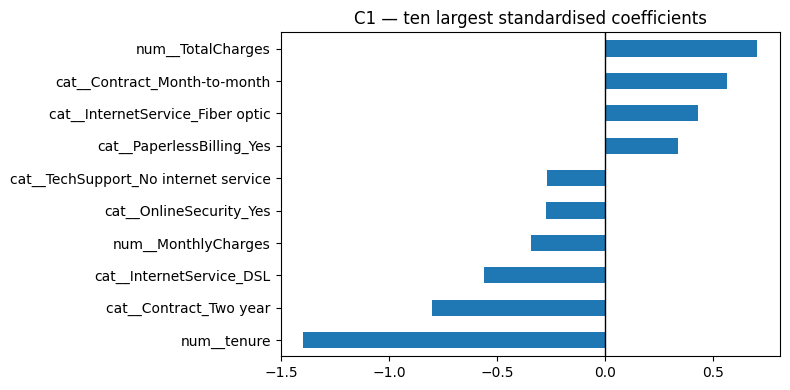

corr(tenure x MonthlyCharges, TotalCharges) = 0.9996
tenure and TotalCharges are in the model together, so the coefficients
trade against each other and stop meaning what their names suggest.


In [8]:
# C1 — code
names = lr[:-1].get_feature_names_out()          # 40 names, post one-hot
coefs = pd.Series(lr[-1].coef_[0], index=names)
top10 = coefs.sort_values(key=abs, ascending=False).head(10)
display(top10.round(3).to_frame('coefficient'))

top10.sort_values().plot.barh(figsize=(8, 4))
plt.axvline(0, color='k', lw=1)
plt.title('C1 — ten largest standardised coefficients'); plt.tight_layout(); plt.show()

# the detail worth catching: MonthlyCharges is NEGATIVE here, but its raw
# correlation with churn in LA01 was +0.193. Why?
prod = tel.tenure * tel.MonthlyCharges
print(f'corr(tenure x MonthlyCharges, TotalCharges) = {prod.corr(tel.TotalCharges):.4f}')
print('tenure and TotalCharges are in the model together, so the coefficients')
print('trade against each other and stop meaning what their names suggest.')

**Observation (C1):**

The ten largest coefficients are tenure (−1.40), Contract: two year (−0.80), TotalCharges
(+0.70), Contract: month-to-month (+0.56), InternetService: DSL (−0.56), fibre optic
(+0.43), MonthlyCharges (−0.34), paperless billing (+0.34), online security (−0.27) and
tech support (−0.27). They are comparable only because the numerics were standardised
inside the pipeline.

All ten are recorded in the billing system and available the moment a score is needed, so
none is leakage in the usual sense. But two caveats matter. First, `tenure` and
`TotalCharges` are zero for a brand-new customer, so this model can score **existing**
customers for retention and cannot be reused to rank acquisition risk, where its strongest
feature carries no information. Second, if scoring runs mid-cycle, `TotalCharges` for the
current month is not final, so the value at prediction time differs from the value trained
on.

`MonthlyCharges` also carries a negative coefficient here while its raw correlation with
churn is positive — the sign flips because `TotalCharges` ≈ `tenure` × `MonthlyCharges`
(correlation 0.999) is in the model too. The predictions are fine; the explanation is not.
I would drop `TotalCharges`, which costs almost nothing in accuracy and makes the remaining
coefficients readable by the retention team.

---

## Self-check before submitting

- [x] Kernel restarted and run top-to-bottom, all outputs visible
- [x] Every attempted question has a written observation
- [x] No transformer fitted outside a pipeline
- [x] Metrics reported for the class that matters, not just the overall average
- [x] File named `AML_LA04_<SAPID>.ipynb`, `README.md` beside it
- [x] No datasets uploaded — the loading code is enough
